# Problem 3: LQR with Gain Scheduling

In this notebook we will:

1. Set up the dynamics of a planar quadrotor (drone) and plot its trajectories.
2. Load a nominal trajectory, computed with a direct method, that takes the quadrotor from hover at $(0, 5)$ to hover at $(10, 7)$ around an obstacle.
3. Simulate what happens if the quadrotor applies the nominal controls open loop in a wind field.
4. (Your task) Implement gain-scheduled LQR so that the quadrotor tracks the nominal trajectory in the wind, and compare a few variants.

All of your code goes in `P3_lqr.py`. The dynamics, wind, and simulator are in `planar_quad.py`; read through it but do not modify it.

## Part 1: Dynamics
We consider a planar (2D) quadrotor

![](https://drive.google.com/uc?export=view&id=1UnEFIpfZWnToer0hIbKAYmKJXrBv5MIE)

with (continuous-time) nonlinear dynamics
$$
    \begin{bmatrix}
      \dot x \\ \dot v_x \\ \dot y \\ \dot v_y \\ \dot \phi \\ \dot \omega
    \end{bmatrix} =
    \begin{bmatrix}
      v_x \\
      \frac{-(T_1 + T_2) \sin\phi - C_D^v v_x}{m} \\
      v_y \\
      \frac{(T_1 + T_2) \cos\phi - C_D^v v_y}{m}  - g \\
      \omega \\
      \frac{(T_2 - T_1) \ell - C_D^\phi \omega}{I_{yy}}
    \end{bmatrix}, \quad T_1, T_2 \in [0, T_{\max}],
$$
where the state is the position in the vertical plane $(x, y)$, translational velocity $(v_x, v_y)$, pitch $\phi$, and pitch rate $\omega$; the controls are the thrusts $(T_1, T_2)$ of the left and right props. The constants $g$, $m$, $I_{yy}$, $\ell$, $C_D^v$, and $C_D^\phi$ are defined in `planar_quad.py`.

In [1]:
%load_ext autoreload
%autoreload 2

import os
import numpy as np
import matplotlib.pyplot as plt

from planar_quad import PlanarQuadrotor, WindField, simulate, plot_obstacle, OBSTACLE_CENTER
from P3_lqr import *

os.makedirs("plots", exist_ok=True)
planar_quad = PlanarQuadrotor()

## Part 2: Nominal Trajectory
The nominal trajectory was computed with `optimize_nominal_trajectory` in `planar_quad.py` (a direct method like the one in Problem 1) and saved to `nominal_trajectory.npz`, so that everyone works with exactly the same plan.

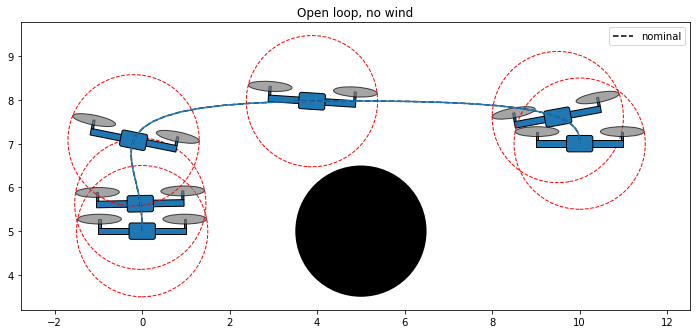

In [2]:
data = np.load("nominal_trajectory.npz")
final_time = float(data["final_time"])
nominal_states = data["nominal_states"]
nominal_controls = data["nominal_controls"]
N = len(nominal_controls)
dt = final_time / N
goal = nominal_states[-1]

def miss_distance(states):
    return np.linalg.norm(states[-1, [0, 2]] - goal[[0, 2]])

def min_obstacle_distance(states):
    return np.min(np.linalg.norm(states[:, [0, 2]] - OBSTACLE_CENTER, axis=1))

def plot_run(states, title, filename=None, wind=None):
    fig, ax = plt.subplots(figsize=(12, 6))
    plot_obstacle(ax, planar_quad)
    if wind is not None:
        wind.plot(ax)
    ax.plot(nominal_states[:, 0], nominal_states[:, 2], 'k--', label="nominal")
    planar_quad.animate(states, dt, ax)
    ax.set_title(title)
    ax.legend()
    if filename is not None:
        plt.savefig(filename, bbox_inches="tight")
    plt.show()

# Without disturbances the nominal controls reproduce the plan exactly
states, _ = simulate(planar_quad, nominal_states[0], lambda k, x: nominal_controls[k], N, dt)
plot_run(states, "Open loop, no wind")

## Part 3: Open Loop in Wind
The wind adds an acceleration $(w_x, w_y)$ to $(\dot v_x, \dot v_y)$ that depends on the position. The wind is zero outside the region where arrows are drawn. The wind values are loaded from `wind_field.npz`.

Open loop: miss distance 8.188 m


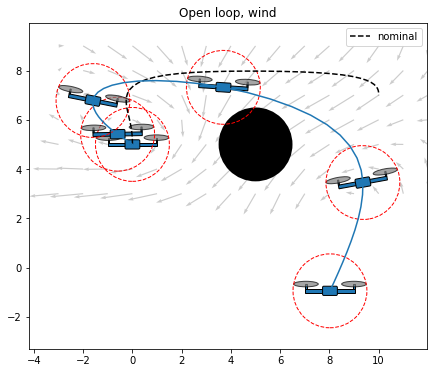

In [3]:
wind = WindField("wind_field.npz")

ol_states, _ = simulate(planar_quad, nominal_states[0], lambda k, x: nominal_controls[k], N, dt, wind)
print(f"Open loop: miss distance {miss_distance(ol_states):.3f} m")
plot_run(ol_states, "Open loop, wind", wind=wind)

## Part 4: Gain-Scheduled LQR
Implement `compute_lqr_gain`, `compute_gain_schedule`, and `lqr_control` in `P3_lqr.py`. The cell below schedules the gains by time: at step $k$ it uses nominal point $j = k$, i.e.
$$u_k = u^*_k - K_k (x_k - x^*_k).$$

Gain-scheduled LQR: miss distance 0.603 m


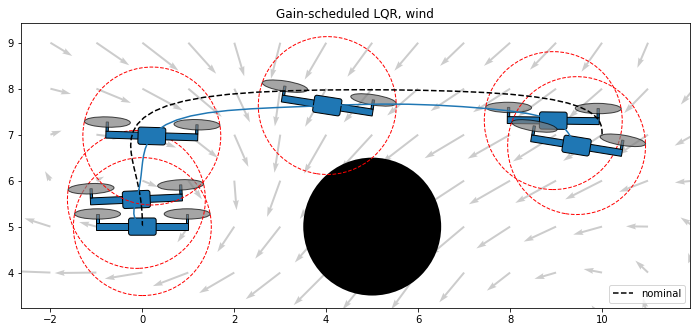

In [4]:
Q = 100 * np.diag([1., 0.1, 1., 0.1, 0.1, 0.1])
R = 1e0 * np.diag([1., 1.])

gains = compute_gain_schedule(planar_quad, nominal_states, nominal_controls, Q, R)
assert len(gains) == N + 1

def time_indexed(gains):
    return lambda k, x: lqr_control(x, k, nominal_states, nominal_controls, gains, planar_quad)

cl_states, cl_controls = simulate(planar_quad, nominal_states[0], time_indexed(gains), N, dt, wind)
print(f"Gain-scheduled LQR: miss distance {miss_distance(cl_states):.3f} m")
plot_run(cl_states, "Gain-scheduled LQR, wind", "plots/p3_closed_loop.png", wind=wind)

## Part 5: Experiments
Use the cells below for parts (ii) and (iii) of the problem.

**Single LQR gain.** Implement `compute_hover_gain`, which linearizes about a level hover only, and use the same gain at every step.

In [5]:
K_hover = compute_hover_gain(planar_quad, Q, R)
hover_states, _ = simulate(planar_quad, nominal_states[0], time_indexed([K_hover] * (N + 1)), N, dt, wind)
print(f"Hover LQR: miss distance {miss_distance(hover_states):.3f} m")
print(f"max |phi| along the nominal trajectory: {np.max(np.abs(nominal_states[:, 4])):.3f} rad")

Hover LQR: miss distance 0.608 m
max |phi| along the nominal trajectory: 0.327 rad


**Scheduling by nearest state.** Implement `find_closest_nominal_state` and schedule by the nominal state closest to the current state instead of by time.

Nearest-state LQR: miss distance 10.348 m
index used at each step: [0, 1, 1, 2, 2, 3, 3, 3, 3, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


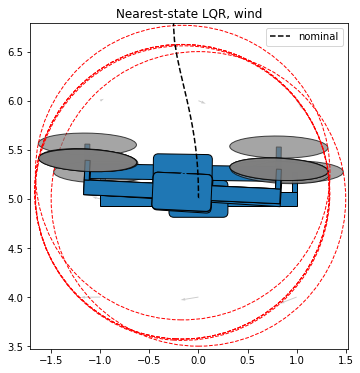

In [6]:
indices = []

def nearest_state(k, x):
    j = find_closest_nominal_state(x, nominal_states)
    indices.append(j)
    return lqr_control(x, j, nominal_states, nominal_controls, gains, planar_quad)

ns_states, _ = simulate(planar_quad, nominal_states[0], nearest_state, N, dt, wind)
print(f"Nearest-state LQR: miss distance {miss_distance(ns_states):.3f} m")
print("index used at each step:", indices)
plot_run(ns_states, "Nearest-state LQR, wind", wind=wind)

**Changing the weights.** Scale $R$ by 100 and compare with the original weights.

R x 100: miss distance 2.186 m, closest approach to obstacle center 1.347 m
R x 1:   miss distance 0.603 m, closest approach to obstacle center 2.672 m


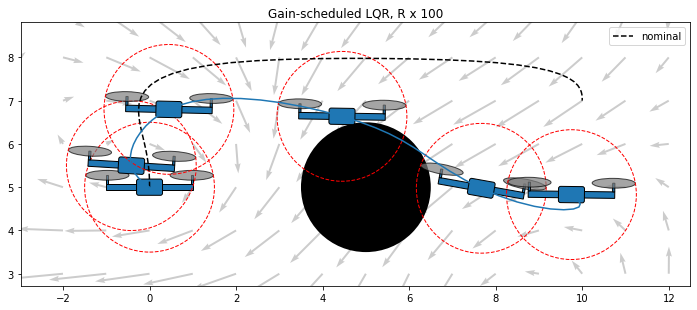

In [7]:
gains_r100 = compute_gain_schedule(planar_quad, nominal_states, nominal_controls, Q, 100 * R)
r100_states, _ = simulate(planar_quad, nominal_states[0], time_indexed(gains_r100), N, dt, wind)
print(f"R x 100: miss distance {miss_distance(r100_states):.3f} m, "
      f"closest approach to obstacle center {min_obstacle_distance(r100_states):.3f} m")
print(f"R x 1:   miss distance {miss_distance(cl_states):.3f} m, "
      f"closest approach to obstacle center {min_obstacle_distance(cl_states):.3f} m")
plot_run(r100_states, "Gain-scheduled LQR, R x 100", "plots/p3_r100.png", wind=wind)